In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train_data=pd.read_csv('train.csv')
train_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
train_data.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
X_train=train_data.drop(labels=['Survived'],axis=1)

In [6]:
X_train.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
y_train=train_data['Survived'].copy()

In [8]:
from sklearn.impute import SimpleImputer
num_imputer=SimpleImputer(strategy="median")
cat_imputer=SimpleImputer(strategy="most_frequent")


In [9]:
len(train_data[train_data["Cabin"].isnull()==True])
# cabin info of 687 passengers is missing

687

In [10]:
# distinct values of Cabin feature and their counts
with pd.option_context('display.max_rows',None): # to see O/P without truncation
    print(train_data["Cabin"].value_counts())

Cabin
B96 B98            4
G6                 4
C23 C25 C27        4
C22 C26            3
F33                3
F2                 3
E101               3
D                  3
C78                2
C93                2
E8                 2
D36                2
B77                2
C123               2
E121               2
E44                2
D35                2
C125               2
E67                2
B35                2
B18                2
E24                2
B49                2
C65                2
B20                2
B5                 2
B57 B59 B63 B66    2
C126               2
B51 B53 B55        2
F4                 2
C124               2
F G73              2
B58 B60            2
C52                2
D33                2
C68                2
D20                2
D26                2
B28                2
C83                2
E25                2
D17                2
B22                2
C92                2
C2                 2
E33                2
C70                1
E58    

Many unique values and also data is messy within many values
So we can also discard the Cabin column

In [11]:
X_train=X_train.drop('Cabin',axis=1)

In [12]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Pclass       891 non-null    int64  
 2   Name         891 non-null    object 
 3   Sex          891 non-null    object 
 4   Age          714 non-null    float64
 5   SibSp        891 non-null    int64  
 6   Parch        891 non-null    int64  
 7   Ticket       891 non-null    object 
 8   Fare         891 non-null    float64
 9   Embarked     889 non-null    object 
dtypes: float64(2), int64(4), object(4)
memory usage: 69.7+ KB


Column transformer changes the oreder of the columns by grouping them according to the transformers you applied rather than keeping the original sequence

In [13]:
train_data["Sex"].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [14]:
train_data["Embarked"].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [15]:
# Building pipeline for numerical columns
from sklearn.pipeline import Pipeline,make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

num_pipeline=Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])


In [78]:
# Building pipeline for categorical columns
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder
cat_pipeline=Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("cat_encoder",OneHotEncoder(sparse_output=False,handle_unknown='ignore'))
])

In [17]:
from sklearn.compose import ColumnTransformer
num_attribs=["Age","SibSp","Parch","Fare"]
cat_attribs=["Pclass","Sex","Embarked"]
preprocess_pipeline=ColumnTransformer([
    ("num_pipeline",num_pipeline,num_attribs),
    ("cat_pipeline",cat_pipeline,cat_attribs)
])

In [18]:
X_train=preprocess_pipeline.fit_transform(X_train)

In [19]:
X_train

array([[-0.56573646,  0.43279337, -0.47367361, ...,  0.        ,
         0.        ,  1.        ],
       [ 0.66386103,  0.43279337, -0.47367361, ...,  1.        ,
         0.        ,  0.        ],
       [-0.25833709, -0.4745452 , -0.47367361, ...,  0.        ,
         0.        ,  1.        ],
       ...,
       [-0.1046374 ,  0.43279337,  2.00893337, ...,  0.        ,
         0.        ,  1.        ],
       [-0.25833709, -0.4745452 , -0.47367361, ...,  1.        ,
         0.        ,  0.        ],
       [ 0.20276197, -0.4745452 , -0.47367361, ...,  0.        ,
         1.        ,  0.        ]], shape=(891, 12))

In [20]:
from sklearn.ensemble import RandomForestClassifier
rd_clf=RandomForestClassifier(random_state=42)
rd_clf.fit(X_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [21]:
full_pipeline=Pipeline([
    ("preprocessing",preprocess_pipeline),
    ("classifier",RandomForestClassifier(random_state=42))
])

In [22]:
test_data=pd.read_csv('test.csv')
test_data.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [23]:
full_pipeline.fit(train_data,y_train)

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num_pipeline', ...), ('cat_pipeline', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [24]:
y_pred=full_pipeline.predict(test_data)

score method requires X_test and y_test ie. true labels but we dont have it so cv score

In [25]:
from sklearn.model_selection import cross_val_score
forest_scores=cross_val_score(full_pipeline,train_data,y_train,cv=10,scoring="accuracy")
forest_scores.mean()

np.float64(0.8103995006242197)

try an SVC

In [26]:
from sklearn.svm import SVC
svc_pipeline=Pipeline([
    ("preprocess_pipeline",preprocess_pipeline),
    ("svc",SVC(gamma="auto"))
])

In [27]:
svc_score=cross_val_score(svc_pipeline,train_data,y_train,cv=10,scoring="accuracy")

In [28]:
svc_score.mean()

np.float64(0.8260549313358302)

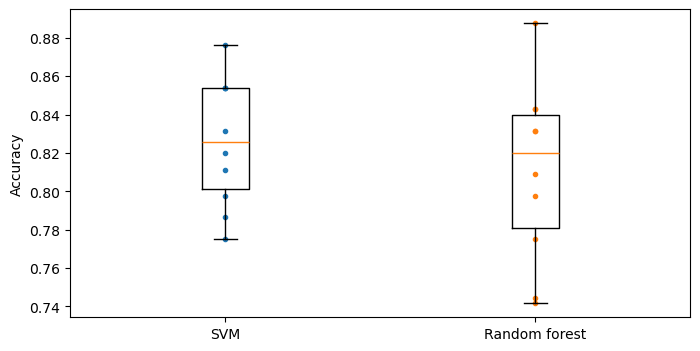

In [29]:
# instead of seeing the mean accuracy of all 10 cv folds
# plotting all the 10 scores of each model on a box plot
plt.figure(figsize=(8,4))
plt.plot([1]*10,svc_score,".")
plt.plot([2]*10,forest_scores,".")
plt.boxplot([svc_score,forest_scores],tick_labels=("SVM","Random forest"))
plt.ylabel("Accuracy")
plt.show()

In [30]:

train_data["Age"].value_counts()

Age
24.00    30
22.00    27
18.00    26
19.00    25
28.00    25
         ..
36.50     1
55.50     1
0.92      1
23.50     1
74.00     1
Name: count, Length: 88, dtype: int64

In [31]:
# different age grps have very different survival rates
train_data["AgeBucket"]=train_data["Age"]//15*15
train_data[["AgeBucket","Survived"]].groupby("AgeBucket").mean()
#Calculates the average of the Survived column for each age bucket. Because Survived is binary (0 or 1), the mean equals the survival rate (percentage) for people in that age grou

,Survived
AgeBucket,
0.0,0.576923
15.0,0.362745
30.0,0.423256
45.0,0.404494
60.0,0.240000
75.0,1.000000


In [32]:
train_data["RelativeOnBoard"]=train_data["SibSp"]+train_data["Parch"]
train_data[["RelativeOnBoard","Survived"]].groupby("RelativeOnBoard").mean()

,Survived
RelativeOnBoard,
0,0.303538
1,0.552795
2,0.578431
3,0.724138
4,0.200000
5,0.136364
6,0.333333
7,0.000000
10,0.000000


In [33]:
train_data["Cabin"].value_counts()

Cabin
B96 B98        4
G6             4
C23 C25 C27    4
C22 C26        3
F33            3
              ..
E34            1
C7             1
C54            1
E36            1
C148           1
Name: count, Length: 147, dtype: int64

In [34]:
train_data["Deck"]=train_data["Cabin"].str.slice(0,1)

In [35]:
res=train_data[["Deck"]].describe() # df
res
# count (non-null values count),top(most freq category),freq(frequency of most frequent category)

,Deck
count,204
unique,8
top,C
freq,59


In [36]:
#percentage of most frequent category
print(59/891*100)

6.621773288439956


In [37]:
train_data[["Deck","Survived"]].groupby("Deck").mean()

,Survived
Deck,
A,0.466667
B,0.744681
C,0.593220
D,0.757576
E,0.750000
F,0.615385
G,0.500000
T,0.000000


In [38]:
train_data["Deck"].fillna("Unknown",inplace=True)

C:\Users\Dell\AppData\Local\Temp\ipykernel_19980\489002662.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  train_data["Deck"].fillna("Unknown",inplace=True)


In [39]:
train_data[["Deck","Survived"]].groupby("Deck").mean()

,Survived
Deck,
A,0.466667
B,0.744681
C,0.593220
D,0.757576
E,0.750000
F,0.615385
G,0.500000
T,0.000000
Unknown,0.299854


In [40]:
pd.set_option('display.max_rows',None)

In [41]:
train_data["Name"]

0                                Braund, Mr. Owen Harris
1      Cumings, Mrs. John Bradley (Florence Briggs Th...
2                                 Heikkinen, Miss. Laina
3           Futrelle, Mrs. Jacques Heath (Lily May Peel)
4                               Allen, Mr. William Henry
5                                       Moran, Mr. James
6                                McCarthy, Mr. Timothy J
7                         Palsson, Master. Gosta Leonard
8      Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)
9                    Nasser, Mrs. Nicholas (Adele Achem)
10                       Sandstrom, Miss. Marguerite Rut
11                              Bonnell, Miss. Elizabeth
12                        Saundercock, Mr. William Henry
13                           Andersson, Mr. Anders Johan
14                  Vestrom, Miss. Hulda Amanda Adolfina
15                      Hewlett, Mrs. (Mary D Kingcome) 
16                                  Rice, Master. Eugene
17                          Wil

In [62]:
train_data["PartOfName"]=train_data["Name"].str.split().str[1]

In [63]:
train_data["PartOfName"]=train_data["PartOfName"].str.rstrip('.')

In [64]:
train_data[["PartOfName"]].head()

,PartOfName
0,Mr
1,Mrs
2,Miss
3,Mrs
4,Mr


In [65]:
train_data["PartOfName"]=train_data["PartOfName"].str.rstrip(',')

In [66]:
train_data[["PartOfName","Survived"]].groupby("PartOfName").mean()

,Survived
PartOfName,
Billiard,0.000000
Capt,0.000000
Carlo,0.000000
Col,0.500000
Cruyssen,0.000000
Don,0.000000
Dr,0.428571
Gordon,1.000000
Impe,0.000000


In [ ]:
# Mapping the rare titles into broader,cleaner groups like Mr,Miss,Mr,Master,Rare
#Mlle (French)-Miss(English),Mme-Mrs,Rare-Col,Major,Dr,Don,Jonkheer,Rev

#rare titles strongly correlated with a significantly lower chance of survival on the Titanic.
#While you might expect passengers with distinguished titles to receive priority treatment
#  because they were wealthy and high-status, 
# the overwhelming factor governing Titanic survival was gender
#  ("women and children first"). 
# Because almost all holders of these specific titles were men,
#  their survival rates were drastically lower than the average for the upper class

In [67]:
title_mapping={
    "Mr":"Mr",
    "Miss":"Miss",
    "Mlle":"Miss",
    "Mme":"Mrs",
    "Master":"Master",
    "Col":"Officer","Major":"Officer","Capt":"Officer",
    "Don":"Noble","Jonkheer":"Noble","Carlo":"Noble",
    "Dr":"Dr","Gordon":"Dr"
}
train_data["PartOfName"]=train_data["PartOfName"].map(title_mapping).fillna('Other')
# map func maps values of a series according to an input mapping or func
#converts unmatched key to Nan

In [68]:
train_data[["PartOfName","Survived"]].groupby("PartOfName").mean()

,Survived
PartOfName,
Dr,0.555556
Master,0.575000
Miss,0.707182
Mr,0.157371
Mrs,1.000000
Noble,0.000000
Officer,0.400000
Other,0.693333


In [69]:
train_data.rename(columns={'PartOfName':'Title'},inplace=True)

In [70]:
train_data[["Title","Survived"]].groupby("Title").mean()

,Survived
Title,
Dr,0.555556
Master,0.575000
Miss,0.707182
Mr,0.157371
Mrs,1.000000
Noble,0.000000
Officer,0.400000
Other,0.693333


In [71]:
train_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,AgeBucket,RelativeOnBoard,Deck,Title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,15.0,1,Unknown,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,30.0,1,C,Other
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,15.0,0,Unknown,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,30.0,1,C,Other
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,30.0,0,Unknown,Mr


In [80]:
from sklearn.compose import ColumnTransformer
num_attribs=['RelativeOnBoard','Fare']
cat_attribs=["Pclass","Sex","Embarked","AgeBucket","Deck","Title"]
preprocess_pipeline=ColumnTransformer([
    ("num_pipeline",num_pipeline,num_attribs),
    ("cat_pipeline",cat_pipeline,cat_attribs)
])

In [81]:
from sklearn.svm import SVC
svm_pipeline=Pipeline([
    ("preprocess",preprocess_pipeline),
    ("svc",SVC(random_state=42))
])

In [82]:
svm_pipeline.fit(train_data,y_train)

,steps,"[('preprocess', ...), ('svc', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num_pipeline', ...), ('cat_pipeline', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [ ]:
cross_val_score(svm_pipeline,train_data,y_train,cv=10,scoring="accuracy").mean()
#accuracy improved slighlty

np.float64(0.8339076154806492)